# 06 — Validación con verdad conocida: provincias y comunas

Los cruces por manzana de la base nacional no se pueden verificar, porque el INE no los publica. A nivel de **comuna**, en cambio, el microdato trae la verdad de cualquier cruce. Aquí se repite el experimento un nivel más arriba para medir el **error real** del modelo:

| | Base nacional | Esta validación |
|---|---|---|
| Unidad grande (conjunta conocida) | comuna | **provincia** |
| Unidades chicas (solo marginales) | manzanas | **comunas** |
| Verdad de los cruces | no existe | **microdato por comuna** |

Para cada provincia se arma la conjunta con el microdato de sus comunas. De cada comuna se usan **solo los mismos 82 marginales univariados** que el INE publica por manzana, calculados desde el microdato. Se ajusta el mismo modelo de 27 bloques, con el mismo código y el mismo criterio de convergencia de la corrida nacional, y se comparan los cruces estimados por comuna con los reales.

**Alternativas de comparación.** Las tres respetan los dos marginales del par o la estructura provincial:
- *independencia:* el cruce sale solo de los dos marginales de la comuna, $n_{a}\,n_{b}/n$;
- *provincial:* la estructura del cruce en la provincia, escalada al tamaño de la comuna (ignora sus marginales);
- *raking de 2 bloques:* el cruce provincial ajustado (IPF) a los dos marginales de la comuna. Usa la provincia y los dos marginales del par, pero no los otros 25 bloques. La diferencia con el modelo es lo que aportan esos 25 bloques.

**Métrica principal: personas mal ubicadas** en el interior del cruce, $\sum|\text{estimado}-\text{real}|\,/\,(2n)$. Como los bordes son dato, mide solo lo inferido. Un 1% significa que habría que mover el 1% de las personas de la comuna de una celda a otra para llegar a la verdad.

**Advertencia de escala.** Aquí las "manzanas" son comunas: miles a cientos de miles de personas, y pocas por provincia (2 a 32). Las manzanas reales tienen ~100 personas y son cientos por comuna. Esto mide el error real **del mecanismo**, pero no se traslada uno a uno: en manzanas, más heterogéneas y donde el azar pesa más, el error relativo seguramente es mayor.

In [1]:
import os
import time

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

from manzanas.inventario import MAPEO_PERSONAS
from manzanas.pais import RUTA_PAIS
from manzanas.provincias import (METODOS, NIVEL_2, RUTA_VALIDACION, ajustar_provincia, celda_por_comuna,
                                 comunas_por_provincia, datos_provincia, evaluar_cruces, evaluar_nivel_2)
from manzanas.perfiles import errores_modelo

pd.set_option("display.width", 250)
os.makedirs(RUTA_VALIDACION, exist_ok=True)

# Paleta (guía de visualización): secuencial de un tono (azul), divergente azul <-> rojo con gris neutro al centro
AZUL = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
SECUENCIAL = LinearSegmentedColormap.from_list("azul", AZUL)
DIVERGENTE = LinearSegmentedColormap.from_list("azul_rojo", ["#104281", "#3987e5", "#9ec5f4", "#f0efec", "#f3a9a3", "#e34948", "#9b1c1c"])
SERIE_1, SERIE_2, SERIE_3 = "#2a78d6", "#eb6834", "#1baf7a"
TEXTO, TEXTO_2, GRILLA = "#0b0b0b", "#52514e", "#e2e1dc"
plt.rcParams.update({"axes.edgecolor": GRILLA, "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
                     "text.color": TEXTO, "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 12, "font.size": 10})
NOMBRES_METODO = {"modelo": "Modelo (27 bloques)", "raking_2": "Raking de 2 bloques", "independencia": "Independencia",
                  "provincial": "Estructura provincial", "condicional_1": "Condicional en 1 bloque", "proporcional": "Proporcional"}

def mal_ubicadas(df, col="err"):
    # % de personas mal ubicadas: sum |estimado - real| / (2 n)
    return 100 * df[col].sum() / (2 * df["n"].sum())
print("resultados en:", RUTA_VALIDACION)

resultados en: resultados/validacion


### V1. Provincias evaluables

Se usan las 295 comunas con inventario completo (sin las 51 bajo umbral). Las provincias con una sola comuna no tienen nada que estimar y quedan fuera.

In [2]:
# V1. Provincias con 2 o más comunas
diag = pd.read_csv(os.path.join(RUTA_PAIS, "diagnostico.csv"), index_col=0)
ok = diag[diag["inventario"] == "ok"]
cpp = comunas_por_provincia(ok.index.tolist())
mapa_comunas = gpd.read_parquet(os.path.join("cartografia_censal", "Cartografia_censo2024_Pais_Comunal.parquet"))
nombre_prov = mapa_comunas.drop_duplicates("COD_PROVINCIA").set_index("COD_PROVINCIA")["PROVINCIA"].to_dict()

provincias = pd.DataFrame({"provincia": [nombre_prov.get(p, str(p)) for p in cpp],
                           "comunas": [len(c) for c in cpp.values()],
                           "personas": [int(ok.loc[c, "personas"].sum()) for c in cpp.values()]}, index=list(cpp))
evaluables = provincias[provincias["comunas"] >= 2]
print(f"provincias: {len(provincias)} | evaluables: {len(evaluables)} con {evaluables['comunas'].sum()} comunas "
      f"y {evaluables['personas'].sum():,} personas ({evaluables['personas'].sum() / ok['personas'].sum():.0%})")
print(evaluables.sort_values("personas", ascending=False).head(8).to_string())

provincias: 51 | evaluables: 43 con 287 comunas y 17,808,383 personas (97%)
      provincia  comunas  personas
131    SANTIAGO       32   5385737
81   CONCEPCIÓN       12   1025448
91       CAUTÍN       21    803777
51   VALPARAÍSO        6    756272
61    CACHAPOAL       17    693308
132  CORDILLERA        3    614587
41        ELQUI        4    553473
134       MAIPO        4    527659


### V2. Ajuste y evaluación de todas las provincias

Para cada provincia: se ajusta el modelo (se guarda en `resultados/validacion/modelos/`), se evalúan los 351 cruces bivariados por comuna contra la verdad con las cuatro estimaciones, y se evalúan las variables sin marginal. Toma unos minutos; la Provincia de Santiago (32 comunas, 5,4 M personas) es la más larga.

In [3]:
# V2. Ajuste + evaluación por provincia (los modelos ya ajustados se cargan)
t_inicio, resumen, cruces, nivel_2 = time.time(), [], [], []
for prov in evaluables.sort_values("personas").index:
    t0 = time.time()
    datos = datos_provincia(prov, cpp[prov], ok["comuna"].to_dict())
    inv, modelo = ajustar_provincia(datos)
    ev = evaluar_cruces(datos, inv, modelo).assign(provincia=prov)
    n2 = evaluar_nivel_2(datos, inv, modelo).assign(provincia=prov)
    cruces.append(ev)
    nivel_2.append(n2)
    resumen.append({"provincia": prov, "nombre": evaluables.loc[prov, "provincia"], "comunas": len(cpp[prov]),
                    "personas": len(datos.personas), "perfiles": len(modelo["mu_p"]), "iteraciones": modelo["iteraciones"],
                    "convergio": modelo["convergio"], "error_marginal_max": max(errores_modelo(inv, modelo).values()),
                    "mal_ubicadas_modelo": mal_ubicadas(ev, "err_modelo"), "mal_ubicadas_raking_2": mal_ubicadas(ev, "err_raking_2"),
                    "mal_ubicadas_independencia": mal_ubicadas(ev, "err_independencia"), "segundos": time.time() - t0})
    print(f"  {prov:>4} {evaluables.loc[prov, 'provincia']:<22} comunas={len(cpp[prov]):>2} | it={modelo['iteraciones']:>5} "
          f"convergió={modelo['convergio']} | mal ubicadas: modelo={resumen[-1]['mal_ubicadas_modelo']:.3f}% "
          f"raking_2={resumen[-1]['mal_ubicadas_raking_2']:.3f}% | {time.time() - t0:.0f}s", flush=True)

resumen = pd.DataFrame(resumen).set_index("provincia")
cruces = pd.concat(cruces, ignore_index=True)
nivel_2 = pd.concat(nivel_2, ignore_index=True)
resumen.to_csv(os.path.join(RUTA_VALIDACION, "resumen_provincias.csv"))
cruces.to_parquet(os.path.join(RUTA_VALIDACION, "errores_cruces.parquet"), index=False)
nivel_2.to_parquet(os.path.join(RUTA_VALIDACION, "errores_nivel_2.parquet"), index=False)
print(f"\n{len(resumen)} provincias en {(time.time() - t_inicio) / 60:.1f} min | todas convergieron: {resumen['convergio'].all()} "
      f"| error marginal máx: {resumen['error_marginal_max'].max():.2f} personas")
assert resumen["convergio"].all()

    14 DEL TAMARUGAL          comunas= 2 | it=  200 convergió=True | mal ubicadas: modelo=0.233% raking_2=0.274% | 0s
    32 CHAÑARAL               comunas= 2 | it=  450 convergió=True | mal ubicadas: modelo=0.193% raking_2=0.226% | 0s
   162 ITATA                  comunas= 4 | it= 1750 convergió=True | mal ubicadas: modelo=0.226% raking_2=0.239% | 1s
    62 CARDENAL CARO          comunas= 5 | it=  700 convergió=True | mal ubicadas: modelo=0.253% raking_2=0.298% | 1s
    72 CAUQUENES              comunas= 3 | it=  350 convergió=True | mal ubicadas: modelo=0.158% raking_2=0.169% | 1s
    33 HUASCO                 comunas= 3 | it=  650 convergió=True | mal ubicadas: modelo=0.130% raking_2=0.146% | 1s
    54 PETORCA                comunas= 5 | it=  700 convergió=True | mal ubicadas: modelo=0.195% raking_2=0.221% | 1s
    42 CHOAPA                 comunas= 4 | it=  300 convergió=True | mal ubicadas: modelo=0.190% raking_2=0.222% | 1s
   142 RANCO                  comunas= 4 | it=  850 conv

### V3. Error global por método

Personas mal ubicadas sumando los 351 cruces de las 287 comunas. Cada comuna pesa según su población; por eso también se muestra la mediana por comuna, donde todas pesan igual.

                       mal ubicadas, total (%)  mal ubicadas, mediana por comuna (%)  el modelo reduce el error en (%)
Modelo (27 bloques)                      0.181                                 0.249                             0.000
Raking de 2 bloques                      0.250                                 0.305                            27.411
Independencia                            4.479                                 4.386                            95.948
Estructura provincial                    3.516                                 3.600                            94.838


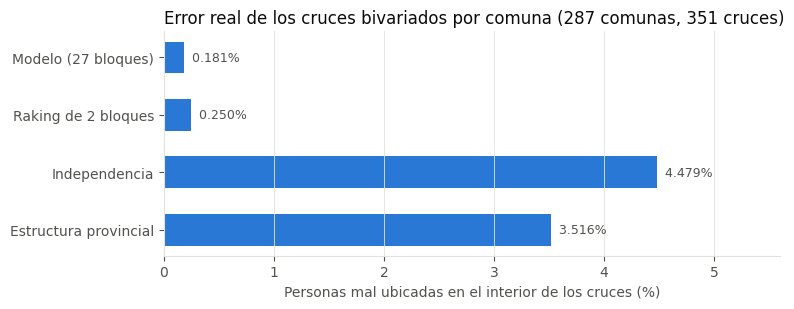

In [4]:
# V3. Error global: personas mal ubicadas en el interior de los cruces, por método
por_comuna = (cruces.groupby("comuna")[[f"err_{m}" for m in METODOS] + ["n"]].sum())
tabla = pd.DataFrame({
    "mal ubicadas, total (%)": [100 * por_comuna[f"err_{m}"].sum() / (2 * por_comuna["n"].sum()) for m in METODOS],
    "mal ubicadas, mediana por comuna (%)": [(100 * por_comuna[f"err_{m}"] / (2 * por_comuna["n"])).median() for m in METODOS],
}, index=[NOMBRES_METODO[m] for m in METODOS])
tabla["el modelo reduce el error en (%)"] = 100 * (1 - tabla.iloc[0, 0] / tabla.iloc[:, 0])
print(tabla.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 3.2))
valores = tabla["mal ubicadas, total (%)"][::-1]
barras = ax.barh(valores.index, valores.to_numpy(), color=SERIE_1, height=0.55)
for barra, v in zip(barras, valores.to_numpy()):
    ax.text(v, barra.get_y() + barra.get_height() / 2, f"  {v:.3f}%", va="center", color=TEXTO_2, fontsize=9)
ax.set_xlabel("Personas mal ubicadas en el interior de los cruces (%)")
ax.set_title("Error real de los cruces bivariados por comuna (287 comunas, 351 cruces)", loc="left")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, valores.max() * 1.25)
plt.tight_layout()
plt.show()

### V4. Error por par de variables

Cada celda es un cruce de dos bloques. A la izquierda, el error del modelo; a la derecha, cuánto lo reduce el modelo respecto del raking de 2 bloques, que es el aporte de los otros 25 bloques. Rojo significa que el modelo es peor que esa alternativa. En blanco quedan los pares que sus dos marginales ya determinan casi por completo (error del raking de 2 bloques < 0,01%), por ejemplo las asistencias, que corresponden cada una a un tramo de edad: ahí no hay nada que inferir y el porcentaje no tiene sentido.

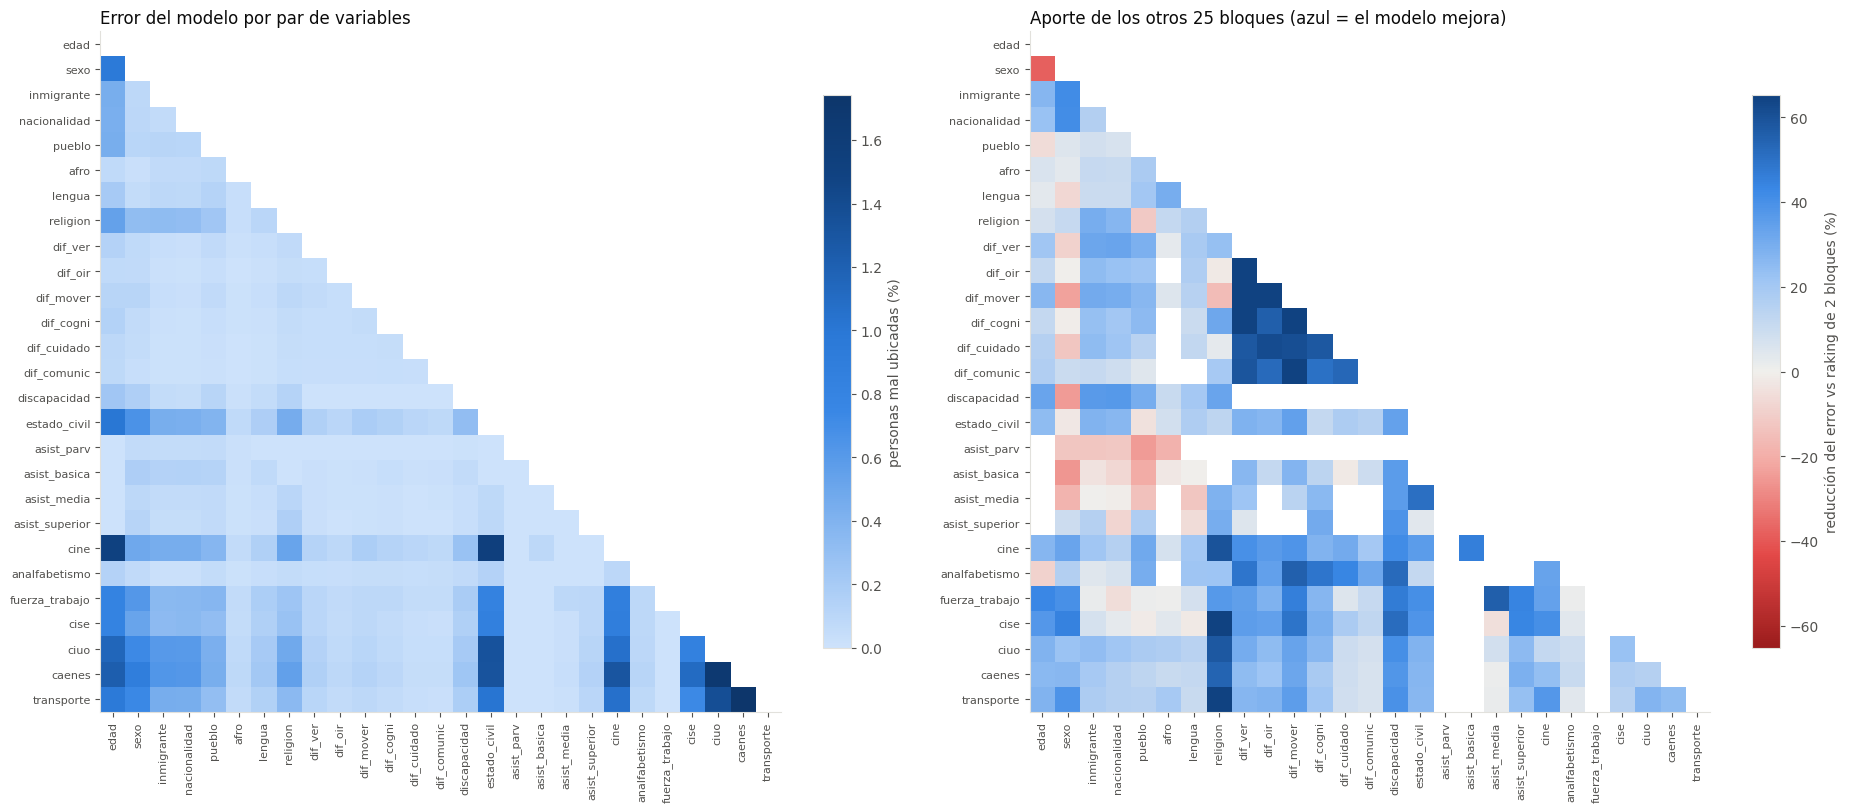

pares con más error del modelo:
                          error modelo (%)  error raking_2 (%)  reducción (%)
var1         var2                                                           
caenes       transporte             1.741               2.319         24.926
ciuo         caenes                 1.665               1.977         15.782
estado_civil cine                   1.535               2.403         36.122
edad         cine                   1.500               2.047         26.731
ciuo         transporte             1.368               1.881         27.303
estado_civil ciuo                   1.327               1.837         27.752
             caenes                 1.325               1.805         26.622
cine         caenes                 1.305               1.707         23.557

pares donde el modelo mejora al raking de 2 bloques: 250 de 287 (otros 64 quedan determinados por sus marginales) | reducción mediana: 20.6%
pares donde el modelo es peor:
                      er

In [5]:
# V4. Error por par de bloques (matrices 27 x 27, triángulo inferior)
bloques = list(MAPEO_PERSONAS)
por_par = cruces.groupby(["var1", "var2"])[[f"err_{m}" for m in METODOS] + ["n"]].sum()
error_par = 100 * por_par["err_modelo"] / (2 * por_par["n"])
error_r2 = 100 * por_par["err_raking_2"] / (2 * por_par["n"])
# pares casi determinados por sus dos marginales: no hay nada que inferir, el % de mejora no aplica
mejora_par = (100 * (1 - por_par["err_modelo"] / por_par["err_raking_2"])).where(error_r2 >= 0.01)
K = len(bloques)
E, G = np.full((K, K), np.nan), np.full((K, K), np.nan)
for (a, b), v in error_par.items():
    E[bloques.index(b), bloques.index(a)] = v
    G[bloques.index(b), bloques.index(a)] = mejora_par[(a, b)]

fig, axes = plt.subplots(1, 2, figsize=(19, 8.5))
im = axes[0].imshow(E, cmap=SECUENCIAL, vmin=0)
fig.colorbar(im, ax=axes[0], shrink=0.7, label="personas mal ubicadas (%)")
axes[0].set_title("Error del modelo por par de variables", loc="left")
lim = np.nanpercentile(np.abs(G), 98)
div = DIVERGENTE.reversed()
div.set_bad("white")
im = axes[1].imshow(np.ma.masked_invalid(G), cmap=div, norm=TwoSlopeNorm(0, -lim, lim))
fig.colorbar(im, ax=axes[1], shrink=0.7, label="reducción del error vs raking de 2 bloques (%)")
axes[1].set_title("Aporte de los otros 25 bloques (azul = el modelo mejora)", loc="left")
for ax in axes:
    ax.set_xticks(range(K), bloques, rotation=90, fontsize=8)
    ax.set_yticks(range(K), bloques, fontsize=8)
    ax.grid(False)
plt.tight_layout()
plt.show()

top = pd.DataFrame({"error modelo (%)": error_par, "error raking_2 (%)": error_r2,
                    "reducción (%)": mejora_par}).round(3)
print("pares con más error del modelo:\n", top.sort_values("error modelo (%)", ascending=False).head(8).to_string())
print(f"\npares donde el modelo mejora al raking de 2 bloques: {(mejora_par > 0).sum()} de {mejora_par.notna().sum()} "
      f"(otros {mejora_par.isna().sum()} quedan determinados por sus marginales) | reducción mediana: {mejora_par.median():.1f}%")
print("pares donde el modelo es peor:\n", top[top["reducción (%)"] < 0].sort_values("reducción (%)").head(8).to_string())

### V5. Error según el tamaño de la comuna

Error por comuna (todos los cruces) contra su población, para el modelo y para el raking de 2 bloques. Si el error crece al achicarse la comuna, en manzanas (mucho más chicas) cabe esperar errores mayores.

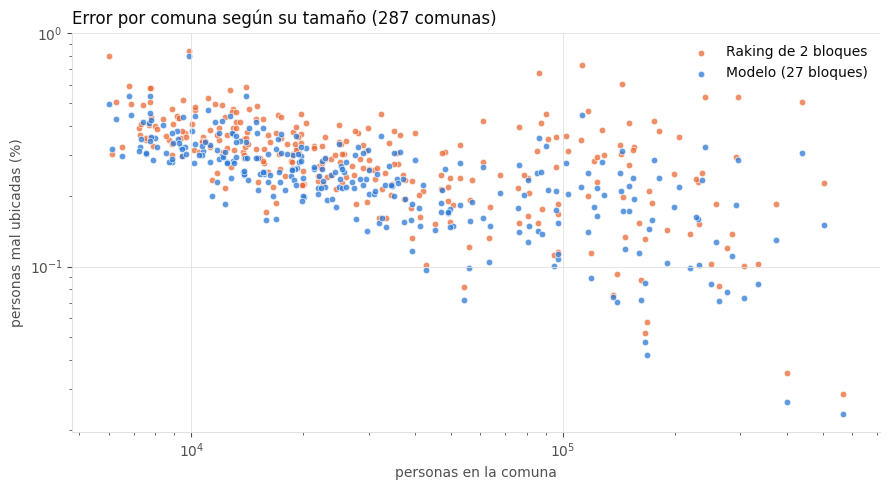

correlación log(tamaño) vs log(error modelo): -0.69
mediana del error del modelo por tamaño de comuna:
            modelo  raking_2
personas                    
<10 mil      0.341     0.402
10–50 mil    0.255     0.307
50–150 mil   0.181     0.239
>150 mil     0.138     0.187


In [6]:
# V5. Error por comuna vs tamaño
pc = por_comuna.assign(modelo=100 * por_comuna["err_modelo"] / (2 * por_comuna["n"]),
                       raking_2=100 * por_comuna["err_raking_2"] / (2 * por_comuna["n"]),
                       personas=por_comuna["n"] / len(por_par))
fig, ax = plt.subplots(figsize=(9, 5))
for col, color, nombre in [("raking_2", SERIE_2, NOMBRES_METODO["raking_2"]), ("modelo", SERIE_1, NOMBRES_METODO["modelo"])]:
    ax.scatter(pc["personas"], pc[col], s=22, color=color, alpha=0.75, edgecolor="white", linewidth=0.6, label=nombre)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("personas en la comuna")
ax.set_ylabel("personas mal ubicadas (%)")
ax.set_title("Error por comuna según su tamaño (287 comunas)", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
print("correlación log(tamaño) vs log(error modelo):", round(np.corrcoef(np.log(pc["personas"]), np.log(pc["modelo"]))[0, 1], 2))
print("mediana del error del modelo por tamaño de comuna:")
print(pc.groupby(pd.cut(pc["personas"], [0, 10_000, 50_000, 150_000, 1e7], labels=["<10 mil", "10–50 mil", "50–150 mil", ">150 mil"]),
                 observed=True)[["modelo", "raking_2"]].median().round(3).to_string())

### V6. Mapas: real vs estimado en la Provincia de Santiago

Una celda de un cruce por comuna, como % de su población. Por defecto, **inmigrantes ocupados**, el mismo cruce del mapa de Independencia en el notebook 05. Arriba, el valor real (microdato) y el estimado por el modelo, en la misma escala. Abajo, el error del modelo y el de la independencia dentro de la comuna, también en la misma escala: rojo = sobreestima, azul = subestima. `PROV_MAPA` y la celda se pueden cambiar.

inmigrantes × ocupado, SANTIAGO: error absoluto medio (puntos porcentuales) -> modelo: 0.314 | raking_2: 0.319 | independencia: 2.286
        nombre     n_per  real_pct  modelo_pct  independencia_pct
18       MAIPÚ  503635.0      3.81        4.01               2.87
0     SANTIAGO  438856.0     29.76       29.65              25.50
9   LA FLORIDA  374836.0      6.54        6.51               4.78
13  LAS CONDES  296134.0      7.18        6.68               5.43
19       ÑUÑOA  241467.0     10.43        9.47               8.20
21   PEÑALOLÉN  236478.0      5.62        5.71               4.14
23    PUDAHUEL  227820.0      4.55        4.75               3.34
24   QUILICURA  205624.0      8.41        8.69               6.35


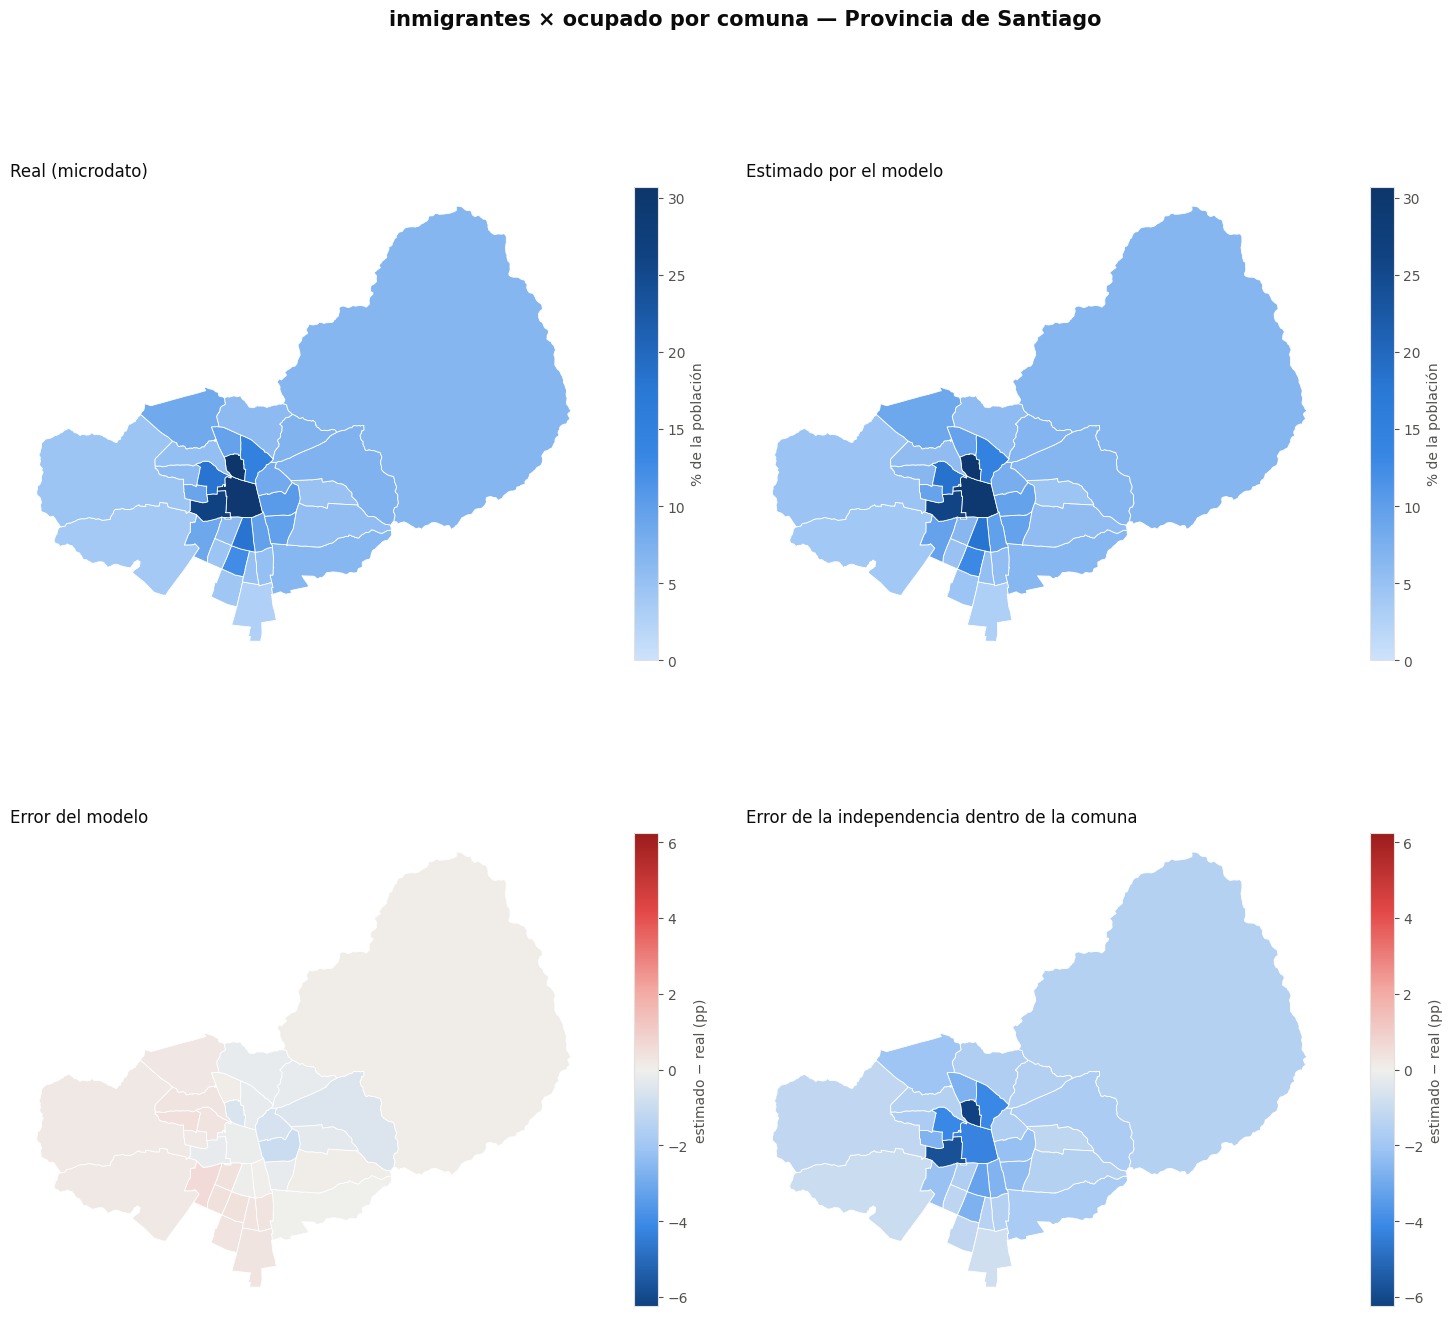

In [7]:
# V6. Mapas de una celda de un cruce: real, estimado y errores
PROV_MAPA = 131  # Provincia de Santiago
VAR1, CAT1, VAR2, CAT2 = "inmigrante", "inmigrantes", "fuerza_trabajo", "ocupado"

datos_m = datos_provincia(PROV_MAPA, cpp[PROV_MAPA], ok["comuna"].to_dict())
inv_m, modelo_m = ajustar_provincia(datos_m)
celda = celda_por_comuna(datos_m, inv_m, modelo_m, VAR1, CAT1, VAR2, CAT2)
for c in ["real", "modelo", "independencia", "raking_2", "provincial"]:
    celda[f"{c}_pct"] = 100 * celda[c] / celda["n_per"]
for c in ["modelo", "independencia", "raking_2"]:
    celda[f"error_{c}"] = celda[f"{c}_pct"] - celda["real_pct"]
print(f"{CAT1} × {CAT2}, {evaluables.loc[PROV_MAPA, 'provincia']}: error absoluto medio (puntos porcentuales) -> "
      + " | ".join(f"{c}: {celda[f'error_{c}'].abs().mean():.3f}" for c in ["modelo", "raking_2", "independencia"]))
print(celda.sort_values("n_per", ascending=False).head(8)[["nombre", "n_per", "real_pct", "modelo_pct", "independencia_pct"]].round(2).to_string())

mapa = mapa_comunas.merge(celda.rename(columns={"comuna": "CUT"}), on="CUT", how="inner")
vmax = np.nanmax(mapa[["real_pct", "modelo_pct"]].to_numpy())
lim = np.nanmax(np.abs(mapa[["error_modelo", "error_independencia"]].to_numpy()))
fig, axes = plt.subplots(2, 2, figsize=(15, 15))
paneles = [(axes[0, 0], "real_pct", "Real (microdato)", dict(cmap=SECUENCIAL, vmin=0, vmax=vmax), "% de la población"),
           (axes[0, 1], "modelo_pct", "Estimado por el modelo", dict(cmap=SECUENCIAL, vmin=0, vmax=vmax), "% de la población"),
           (axes[1, 0], "error_modelo", "Error del modelo", dict(cmap=DIVERGENTE, norm=TwoSlopeNorm(0, -lim, lim)), "estimado − real (pp)"),
           (axes[1, 1], "error_independencia", "Error de la independencia dentro de la comuna",
            dict(cmap=DIVERGENTE, norm=TwoSlopeNorm(0, -lim, lim)), "estimado − real (pp)")]
for ax, col, titulo, kw, etiqueta in paneles:
    mapa.plot(column=col, ax=ax, edgecolor="white", linewidth=0.6, legend=True,
              legend_kwds={"label": etiqueta, "shrink": 0.6}, **kw)
    ax.set_title(titulo, loc="left")
    ax.axis("off")
plt.suptitle(f"{CAT1} × {CAT2} por comuna — Provincia de {evaluables.loc[PROV_MAPA, 'provincia'].title()}", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### V7. Mapa del error total por comuna

Personas mal ubicadas en las 351 tablas de cada comuna de la Provincia de Santiago, para el modelo y para el raking de 2 bloques, en la misma escala.

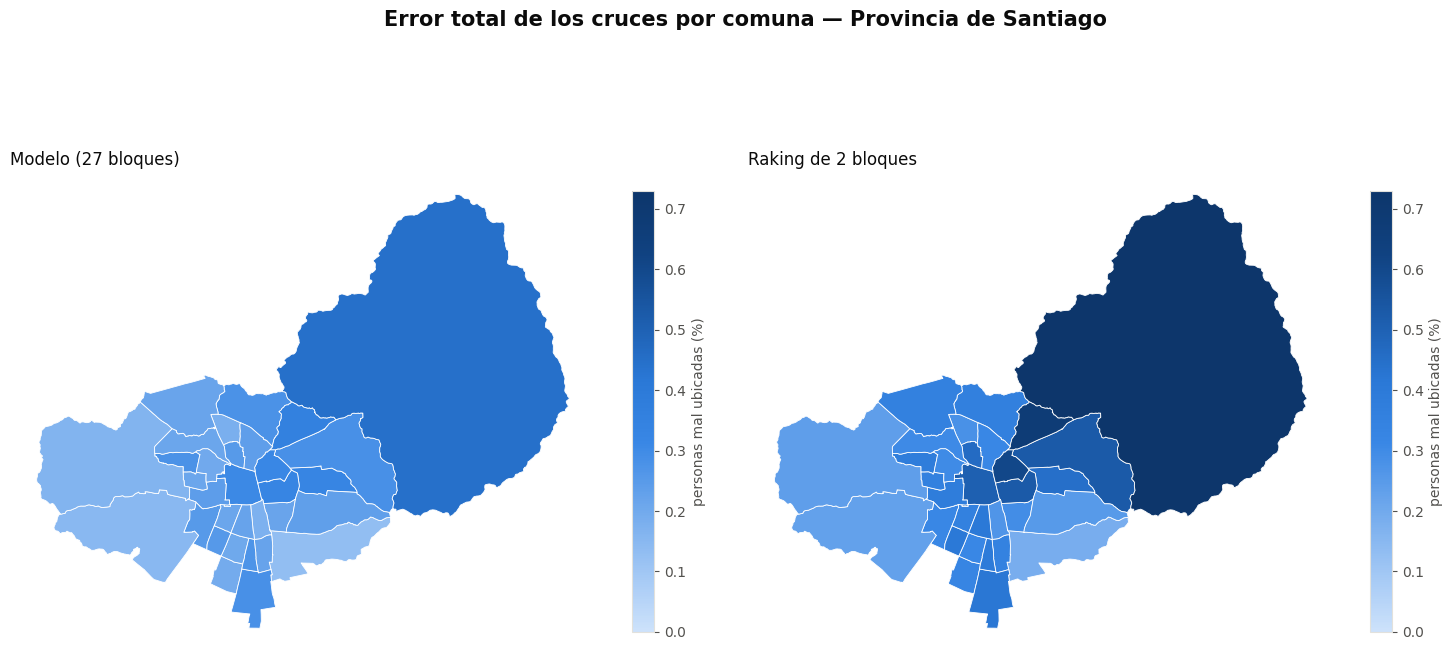

  CUT  modelo  raking_2       comuna
13115   0.447     0.730 LO BARNECHEA
13132   0.356     0.676     VITACURA
13113   0.329     0.449     LA REINA
13120   0.324     0.530        ÑUÑOA
13123   0.313     0.607  PROVIDENCIA


In [8]:
# V7. Error total por comuna (todos los cruces), modelo vs raking de 2 bloques
err_prov = pc[pc.index.isin(cpp[PROV_MAPA])][["modelo", "raking_2"]].rename_axis("CUT").reset_index()
mapa_e = mapa_comunas.merge(err_prov, on="CUT", how="inner")
vmax = mapa_e[["modelo", "raking_2"]].to_numpy().max()
fig, axes = plt.subplots(1, 2, figsize=(15, 8))
for ax, col in zip(axes, ["modelo", "raking_2"]):
    mapa_e.plot(column=col, ax=ax, cmap=SECUENCIAL, vmin=0, vmax=vmax, edgecolor="white", linewidth=0.6, legend=True,
                legend_kwds={"label": "personas mal ubicadas (%)", "shrink": 0.6})
    ax.set_title(NOMBRES_METODO[col], loc="left")
    ax.axis("off")
plt.suptitle(f"Error total de los cruces por comuna — Provincia de {evaluables.loc[PROV_MAPA, 'provincia'].title()}", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()
print(err_prov.merge(ok[["comuna"]], left_on="CUT", right_index=True).sort_values("modelo", ascending=False).head(5).round(3).to_string(index=False))

### V8. Variables sin marginal por manzana

Para las variables que no tienen marginal publicado, la base no las trae, pero se pueden armar desde $W$: cada persona hereda el reparto espacial de su perfil. Se compara contra lo que se haría sin modelo: repartir según la distribución provincial (*proporcional*), o condicionar solo en el bloque más relacionado (*condicional en 1 bloque*: inmigrante para país de nacimiento, pueblo para pueblo específico, CINE para escolaridad y edad para parentesco).

                     Modelo (27 bloques)  Condicional en 1 bloque  Proporcional  categorías
variable                                                                                   
años de escolaridad                2.542                    3.631         8.080          26
parentesco                         2.208                    3.445         3.829          18
país de nacimiento                 0.954                    1.326         4.068          15
pueblo específico                  0.284                    0.352         2.669          13


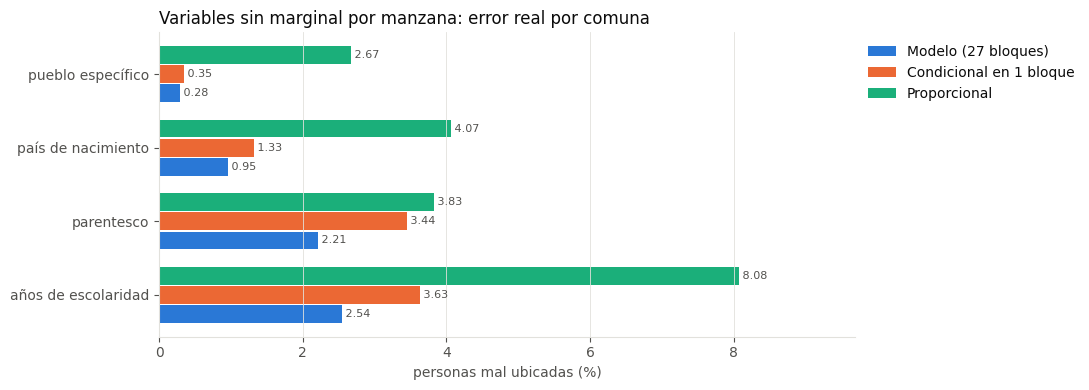

In [9]:
# V8. Variables sin marginal: extensión por perfil vs alternativas
t2 = (nivel_2.groupby(["variable", "metodo"]).apply(lambda d: mal_ubicadas(d), include_groups=False).unstack()
      [["modelo", "condicional_1", "proporcional"]])
t2.columns = [NOMBRES_METODO[c] for c in t2.columns]
t2["categorías"] = nivel_2.groupby("variable")["categorias"].max()
print(t2.round(3).to_string())

fig, ax = plt.subplots(figsize=(11, 4))
y = np.arange(len(t2))
for k, (col, color) in enumerate(zip(t2.columns[:3], [SERIE_1, SERIE_2, SERIE_3])):
    barras = ax.barh(y + (k - 1) * 0.26, t2[col], height=0.24, color=color, label=col)
    for barra, v in zip(barras, t2[col]):
        ax.text(v, barra.get_y() + barra.get_height() / 2, f" {v:.2f}", va="center", color=TEXTO_2, fontsize=8)
ax.set_yticks(y, t2.index)
ax.set_xlabel("personas mal ubicadas (%)")
ax.set_title("Variables sin marginal por manzana: error real por comuna", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_xlim(0, t2.iloc[:, :3].to_numpy().max() * 1.2)
plt.tight_layout()
plt.show()

### Conclusiones

1. **El modelo acierta el interior de los cruces casi por completo a esta escala.** Deja un **0,18%** de personas mal ubicadas en el interior de los 351 cruces (mediana por comuna: 0,25%). Comparado con las alternativas:
   - raking de 2 bloques: 0,25%, o sea **27% menos error** con el modelo;
   - estructura provincial: 3,5%;
   - independencia dentro de la comuna: 4,5%, **96% menos error** con el modelo.

   Lo esencial lo aporta la estructura de la provincia ajustada a los bordes de la comuna. Los otros 25 bloques reducen el error restante en una quinta parte más.

2. **Los otros 25 bloques mejoran 250 de los 287 cruces que no están determinados por sus marginales,** con una reducción mediana de 21%. Los cruces más difíciles son los de muchas categorías ligados a trabajo y educación: rama × transporte (1,7%), ocupación × rama (1,7%), estado civil × CINE (1,5%) y edad × CINE (1,5%).

3. **El modelo empeora en los cruces con sexo,** sobre todo **edad × sexo** (0,96% contra 0,70% del raking de 2 bloques). Los marginales de variables muy marcadas por sexo, como la rama o la ocupación, empujan la razón hombre/mujer de cada tramo de edad suponiendo que la relación de la provincia vale en cada comuna, y esa relación no se transfiere bien. Es consistente con el LOO interno del notebook 02, donde el modelo tampoco mejoraba la predicción del sexo. Los errores absolutos son chicos.

4. **El error crece al achicarse la unidad.** La mediana por comuna va de 0,14% (más de 150 mil personas) a 0,34% (menos de 10 mil), con correlación −0,69 en escala log. En manzanas de ~100 personas cabe esperar errores mayores que los medidos aquí. Extrapolar la tendencia hasta ese tamaño sería especulativo.

5. **Variables sin marginal (extensión por perfil):** el modelo supera a las dos alternativas en las cuatro variables evaluadas. En años de escolaridad deja 2,5%, contra 3,6% condicionando solo en CINE y 8,1% proporcional. En país de nacimiento, 0,95% contra 1,33% (solo inmigrante) y 4,1%.

6. **Mapas de Santiago (inmigrantes ocupados):** el error medio del modelo es 0,31 puntos porcentuales, contra 2,3 de la independencia. Para esta celda el raking de 2 bloques es igual de bueno (0,32): la información clave está en los dos marginales y en la estructura provincial.

**Límite de esta validación:** comunas y provincias son unidades grandes y la estructura de la provincia se parece más a la de cada comuna que la de una comuna a la de cada manzana. Por eso estos errores son una cota optimista del error a nivel de manzana.